<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Task 1: DAG Nodes & Edges ===
Nodes: ['Smoking', 'Lung_Disease', 'Pollution', 'Cough', 'Xray_Result', 'Fatigue']
Edges: [('Smoking', 'Lung_Disease'), ('Lung_Disease', 'Cough'), ('Lung_Disease', 'Xray_Result'), ('Lung_Disease', 'Fatigue'), ('Pollution', 'Lung_Disease'), ('Cough', 'Fatigue')] 

=== Task 2: Conditional Probability Tables (CPDs) ===
+--------------+-----+
| Smoking(No)  | 0.7 |
+--------------+-----+
| Smoking(Yes) | 0.3 |
+--------------+-----+ 

+-----------------+-----+
| Pollution(Low)  | 0.8 |
+-----------------+-----+
| Pollution(High) | 0.2 |
+-----------------+-----+ 

+-----------------------+-----+----------------+-----------------+
| Smoking               | ... | Smoking(Yes)   | Smoking(Yes)    |
+-----------------------+-----+----------------+-----------------+
| Pollution             | ... | Pollution(Low) | Pollution(High) |
+-----------------------+-----+----------------+-----------------+
| Lung_Disease(Absent)  | ... | 0.85           | 0.65           

/tmp/ipykernel_3003/651878772.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


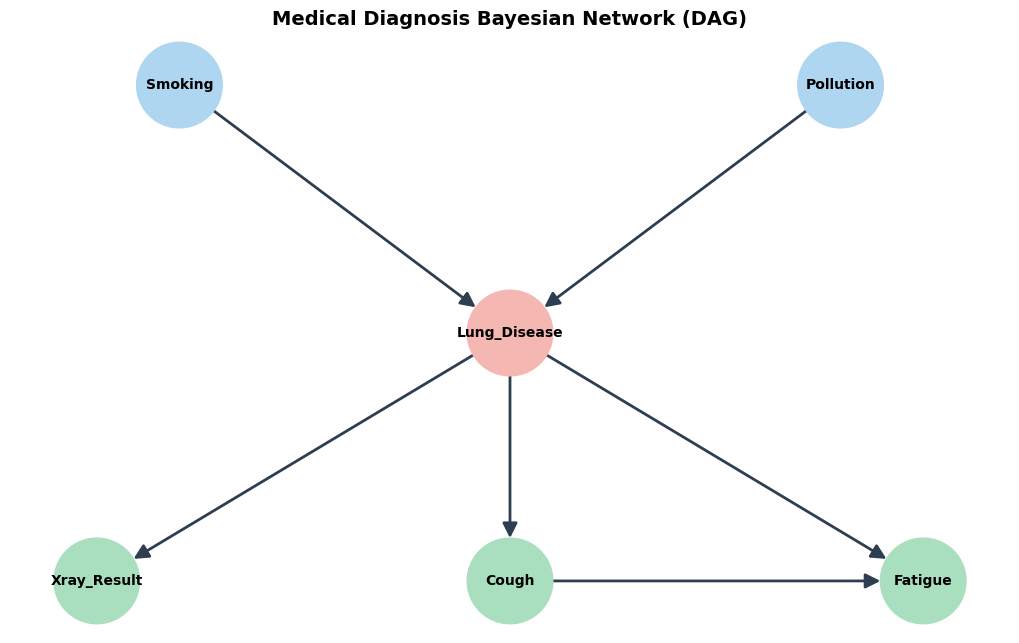

=== Task 5a: Local Conditional Independencies ===
  Smoking       : (Smoking ⟂ Pollution)
  Lung_Disease  : 
  Pollution     : (Pollution ⟂ Smoking)
  Cough         : (Cough ⟂ Pollution, Smoking, Xray_Result | Lung_Disease)
  Xray_Result   : (Xray_Result ⟂ Cough, Fatigue, Pollution, Smoking | Lung_Disease)
  Fatigue       : (Fatigue ⟂ Pollution, Smoking, Xray_Result | Cough, Lung_Disease)

=== Task 5b: Active Trails Analysis ===
1. Active trail from 'Smoking' (no evidence):
   {'Smoking': {'Lung_Disease', 'Cough', 'Fatigue', 'Smoking', 'Xray_Result'}}
2. Active trail from 'Smoking' given 'Lung_Disease' is observed (explaining-away collider):
   {'Smoking': {'Smoking', 'Pollution'}}
3. Active trail from 'Xray_Result' given 'Lung_Disease' is observed (d-separated from symptoms/causes):
   {'Xray_Result': {'Xray_Result'}}
4. Active trail from 'Cough' given 'Lung_Disease' is observed:
   {'Cough': {'Cough', 'Fatigue'}}


In [ ]:
!pip install -q pgmpy networkx matplotlib

import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.factors.discrete import TabularCPD

# Handle pgmpy version differences (v1.0+ uses DiscreteBayesianNetwork)
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork

# ==========================================
# Task 1: Define the Directed Acyclic Graph (DAG) in pgmpy
# ==========================================
edges = [
    ("Smoking", "Lung_Disease"),
    ("Pollution", "Lung_Disease"),
    ("Lung_Disease", "Cough"),
    ("Lung_Disease", "Xray_Result"),
    ("Lung_Disease", "Fatigue"),
    ("Cough", "Fatigue"),
]

model = BayesianNetwork(edges)
print("=== Task 1: DAG Nodes & Edges ===")
print("Nodes:", list(model.nodes()))
print("Edges:", list(model.edges()), "\n")

# ==========================================
# Task 2: Specify Conditional Probability Distributions (CPDs)
# ==========================================
# Prior: Smoking (No=0, Yes=1)
cpd_smoking = TabularCPD(
    variable="Smoking", variable_card=2,
    values=[[0.70], [0.30]],
    state_names={"Smoking": ["No", "Yes"]}
)

# Prior: Pollution (Low=0, High=1)
cpd_pollution = TabularCPD(
    variable="Pollution", variable_card=2,
    values=[[0.80], [0.20]],
    state_names={"Pollution": ["Low", "High"]}
)

# P(Lung_Disease | Smoking, Pollution)
# Columns: (No, Low), (No, High), (Yes, Low), (Yes, High)
cpd_lung = TabularCPD(
    variable="Lung_Disease", variable_card=2,
    values=[
        [0.98, 0.90, 0.85, 0.65],  # Absent
        [0.02, 0.10, 0.15, 0.35],  # Present
    ],
    evidence=["Smoking", "Pollution"],
    evidence_card=[2, 2],
    state_names={
        "Lung_Disease": ["Absent", "Present"],
        "Smoking": ["No", "Yes"],
        "Pollution": ["Low", "High"]
    }
)

# P(Cough | Lung_Disease)
cpd_cough = TabularCPD(
    variable="Cough", variable_card=2,
    values=[
        [0.85, 0.20],  # No
        [0.15, 0.80],  # Yes
    ],
    evidence=["Lung_Disease"],
    evidence_card=[2],
    state_names={"Cough": ["No", "Yes"], "Lung_Disease": ["Absent", "Present"]}
)

# P(Xray_Result | Lung_Disease)
cpd_xray = TabularCPD(
    variable="Xray_Result", variable_card=2,
    values=[
        [0.95, 0.15],  # Normal
        [0.05, 0.85],  # Positive
    ],
    evidence=["Lung_Disease"],
    evidence_card=[2],
    state_names={"Xray_Result": ["Normal", "Positive"], "Lung_Disease": ["Absent", "Present"]}
)

# P(Fatigue | Lung_Disease, Cough)
# Columns: (Absent, No), (Absent, Yes), (Present, No), (Present, Yes)
cpd_fatigue = TabularCPD(
    variable="Fatigue", variable_card=2,
    values=[
        [0.90, 0.65, 0.40, 0.15],  # No
        [0.10, 0.35, 0.60, 0.85],  # Yes
    ],
    evidence=["Lung_Disease", "Cough"],
    evidence_card=[2, 2],
    state_names={
        "Fatigue": ["No", "Yes"],
        "Lung_Disease": ["Absent", "Present"],
        "Cough": ["No", "Yes"]
    }
)

model.add_cpds(cpd_smoking, cpd_pollution, cpd_lung, cpd_cough, cpd_xray, cpd_fatigue)

print("=== Task 2: Conditional Probability Tables (CPDs) ===")
for cpd in model.get_cpds():
    print(cpd, "\n")

# ==========================================
# Task 3: Validate the Model with check_model()
# ==========================================
is_valid = model.check_model()
print(f"=== Task 3: Model Validation ===\ncheck_model() passed: {is_valid}\n")

# ==========================================
# Task 4: Draw the Network with NetworkX
# ==========================================
G = nx.DiGraph(edges)
pos = {
    "Smoking":      (-1.2,  2.0),
    "Pollution":    ( 1.2,  2.0),
    "Lung_Disease": ( 0.0,  1.0),
    "Xray_Result":  (-1.5,  0.0),
    "Cough":        ( 0.0,  0.0),
    "Fatigue":      ( 1.5,  0.0),
}

node_colors = [
    "#AED6F1" if n in ["Smoking", "Pollution"] else
    "#F5B7B1" if n == "Lung_Disease" else
    "#A9DFBF"
    for n in G.nodes()
]

plt.figure(figsize=(10, 6))
nx.draw(
    G, pos,
    with_labels=True,
    node_color=node_colors,
    node_size=3800,
    font_size=10,
    font_weight="bold",
    arrows=True,
    arrowsize=22,
    edge_color="#2C3E50",
    width=2.0
)
plt.title("Medical Diagnosis Bayesian Network (DAG)", fontsize=14, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

# ==========================================
# Task 5: List Conditional Independencies & Active Trails
# ==========================================
print("=== Task 5a: Local Conditional Independencies ===")
for node in model.nodes():
    print(f"  {node:14s}: {model.local_independencies(node)}")

print("\n=== Task 5b: Active Trails Analysis ===")
print("1. Active trail from 'Smoking' (no evidence):")
print("  ", model.active_trail_nodes("Smoking"))

print("2. Active trail from 'Smoking' given 'Lung_Disease' is observed (explaining-away collider):")
print("  ", model.active_trail_nodes("Smoking", observed="Lung_Disease"))

print("3. Active trail from 'Xray_Result' given 'Lung_Disease' is observed (d-separated from symptoms/causes):")
print("  ", model.active_trail_nodes("Xray_Result", observed="Lung_Disease"))

print("4. Active trail from 'Cough' given 'Lung_Disease' is observed:")
print("  ", model.active_trail_nodes("Cough", observed="Lung_Disease"))